# Table 6 — Simple 2-Stage Transfer Learning: Proxy Pretrain → NCV-888 Fine-tune

| Stage | Data | N | Labels | Model type |
|-------|------|---|--------|------------|
| Direct training (proxy-only) | `proxy-DILI_dataset_12133.csv` − held-out-223 | ~7.9 K | Proxy DILI | RF, XGB |
| Direct training (proxy+NCV) | proxy train + `ncv_train` (80 % of NCV-888) | ~8.6 K | Proxy + gold | RF, XGB |
| **Stage 1 — pretrain** | `proxy-DILI_dataset_12133.csv` − held-out-223 | ~7.9 K | Proxy DILI | Graphormer, GraphGPS |
| **Stage 2 — fine-tune** | `test_data_ncv_DILIst_888.csv` (80 %) | ~710 | Gold DILI | Graphormer, GraphGPS |
| **Test — never touched** | `test_data_heldouttest_DILIst_223.csv` | 223 | Gold DILI | All models |

**Why pre-train on proxy then fine-tune on NCV-888?**
The proxy dataset (~7.9 K) provides indirect hepatotoxicity labels (LivTox / Mulliner et al. 2016) — larger but noisy.
Pretraining on it gives the GT encoder a warm start on liver-toxicity patterns before adapting to the smaller (888 compound)
but high-quality human clinical DILI gold standard. This mirrors the ULMFiT / domain-adaptation principle: noisy large source → clean small target.

**Leakage prevention:** held-out-223 is removed from the proxy set before any training. NCV-888 has 0 overlap with the proxy dataset.

In [16]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import copy

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs
RDLogger.DisableLog('rdApp.*')

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, matthews_corrcoef, confusion_matrix,
                              roc_curve, average_precision_score, f1_score)
from xgboost import XGBClassifier

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GINConv, GATConv, TransformerConv, GINEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.utils import get_laplacian, to_dense_adj, degree as pyg_degree

SEED    = 42
BASE    = '/Users/yaminichitikela/Desktop/qsar casepase'
DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
HIDDEN  = 256
N_LAYERS = 4
PE_DIM  = 8
BOND_DIM = 6

np.random.seed(SEED); torch.manual_seed(SEED)
print(f'Device: {DEVICE}')

Device: cpu


---
## Step 1 — Load Datasets & Leakage Check

- **Held-out-223** (`test_data_heldouttest_DILIst_223.csv`): final test set, **never** used during training or HP selection. Its SMILES are removed from the proxy set.
- **Proxy** (`proxy-DILI_dataset_12133.csv`): hepatotoxicity labels from LivTox / Mulliner et al. 2016. Held-out-223 overlaps removed. Used for **Stage 1 pretraining** for GTs and proxy-only RF/XGB.
- **NCV-888** (`test_data_ncv_DILIst_888.csv`): 888 gold-standard clinical DILI compounds. 80/20 split → `ncv_train` / `ncv_val`. Used for **Stage 2 fine-tuning** (GTs) and RF/XGB HP selection. Has 0 overlap with proxy.

In [17]:
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except:
        return None

# ── Held-out-223 (final test — NEVER used during training) ───────────────────
held_df = pd.read_csv(f'{BASE}/liver/test_data_heldouttest_DILIst_223.csv',
                      usecols=['smiles_r', 'TOXICITY'])
held_df['csmi'] = held_df['smiles_r'].apply(canonicalize)
held_df = (held_df.dropna(subset=['csmi'])
                  .drop_duplicates('csmi')
                  .reset_index(drop=True)
                  [['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'}))
held_smiles = set(held_df['csmi'])
print(f'Held-223  : {len(held_df):,}  DILI+={held_df.label.sum():,}  '
      f'DILI-={(held_df.label==0).sum():,}')

# ── Proxy dataset — remove overlap with held-out-223 ─────────────────────────
proxy_raw = pd.read_csv(f'{BASE}/liver/proxy-DILI_dataset_12133.csv',
                        usecols=['smiles_r', 'TOXICITY'])
proxy_raw['csmi'] = proxy_raw['smiles_r'].apply(canonicalize)
proxy_raw = (proxy_raw.dropna(subset=['csmi'])
                      .drop_duplicates('csmi')
                      .reset_index(drop=True))
n_overlap = proxy_raw['csmi'].isin(held_smiles).sum()
proxy_df  = (proxy_raw[~proxy_raw['csmi'].isin(held_smiles)]
             .reset_index(drop=True)
             [['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'}))
print(f'\nProxy raw             : {len(proxy_raw):,}')
print(f'Removed (∩ held-223) : {n_overlap:,}')
print(f'Proxy clean           : {len(proxy_df):,}  DILI+={proxy_df.label.sum():,}  '
      f'DILI-={(proxy_df.label==0).sum():,}')

# ── NCV-888 (fine-tune / HP-selection data) ───────────────────────────────────
ncv_raw = pd.read_csv(f'{BASE}/liver/test_data_ncv_DILIst_888.csv',
                      usecols=['smiles_r', 'TOXICITY'])
ncv_raw['csmi'] = ncv_raw['smiles_r'].apply(canonicalize)
ncv_df  = (ncv_raw.dropna(subset=['csmi'])
                  .drop_duplicates('csmi')
                  .reset_index(drop=True)
                  [['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'}))
print(f'\nNCV-888 : {len(ncv_df):,}  DILI+={ncv_df.label.sum():,}  '
      f'DILI-={(ncv_df.label==0).sum():,}')
print(f'NCV-888 ∩ proxy (expected 0) : {ncv_df["csmi"].isin(set(proxy_df["csmi"])).sum():,}')

Held-223  : 222  DILI+=155  DILI-=67

Proxy raw             : 7,873
Removed (∩ held-223) : 0
Proxy clean           : 7,873  DILI+=2,883  DILI-=4,990

NCV-888 : 874  DILI+=553  DILI-=321
NCV-888 ∩ proxy (expected 0) : 0


---
## Step 2 — Feature Engineering: ECFP4 + Molecular Graphs

All models share the same 2048-bit ECFP4 fingerprints for RF/XGB.  
GNNs and Graph Transformers use molecular graphs with **23-dim atom features** and **6-dim bond features** (`edge_attr`).  
Graphormer uses `edge_attr` directly; GraphGPS additionally appends an 8-dim Laplacian positional encoding.  
No architecture-specific graph format is needed — `mol_to_graph` produces one unified graph per molecule.

In [18]:
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

ATOM_SYMBOLS = [6, 7, 8, 16, 9, 15, 17, 35, 53]

def one_hot(val, choices):
    v = [0] * len(choices)
    try:
        v[choices.index(val)] = 1
    except ValueError:
        pass
    return v

def atom_features(atom):
    return (one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [1]
            + one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5])
            + [atom.GetFormalCharge()]
            + one_hot(int(atom.GetHybridization()), [2, 3, 4, 5])
            + [int(atom.GetIsAromatic()), int(atom.IsInRing())])

def bond_features(bond):
    bt = bond.GetBondTypeAsDouble()
    return [bt == 1.0, bt == 1.5, bt == 2.0, bt == 3.0,
            int(bond.GetIsConjugated()), int(bond.IsInRing())]

def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float)
    if mol.GetNumBonds() == 0:
        edge_index = torch.zeros((2, 0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    else:
        edges, attrs = [], []
        for b in mol.GetBonds():
            i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
            bf = bond_features(b)
            edges += [[i, j], [j, i]]
            attrs += [bf, bf]
        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(attrs, dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                y=torch.tensor([label], dtype=torch.float))

ATOM_DIM = len(atom_features(Chem.MolFromSmiles('C').GetAtomWithIdx(0)))
print(f'Atom feature dim : {ATOM_DIM}')
print(f'Bond feature dim : {BOND_DIM}')

def build_features(df, name):
    fps = df['csmi'].apply(smiles_to_ecfp4)
    ok  = fps.notna().values
    df  = df[ok].reset_index(drop=True)
    X   = np.vstack(fps[ok].values)
    y   = df['label'].values.astype(int)
    graphs_raw = [mol_to_graph(smi, int(lbl)) for smi, lbl in zip(df['csmi'], y)]
    g_ok   = np.array([g is not None for g in graphs_raw])
    graphs = [g for g, v in zip(graphs_raw, g_ok) if v]
    X = X[g_ok]; y = y[g_ok]; df = df[g_ok].reset_index(drop=True)
    print(f'{name}: {len(df):,}  DILI+={int(y.sum()):,}  DILI-={int((y==0).sum()):,}')
    return df, X, y, graphs

Atom feature dim : 23
Bond feature dim : 6


In [19]:
print('Building ECFP4 + graph features for all datasets...')
proxy_df, X_proxy, y_proxy, proxy_graphs = build_features(proxy_df, 'Proxy (clean)')
ncv_df,   X_ncv,  y_ncv,   ncv_graphs   = build_features(ncv_df,   'NCV-888')
held_df,  X_held, y_held,  held_graphs  = build_features(held_df,  'Held-out-223 (test)')

held_loader = DataLoader(held_graphs, batch_size=64)
print('\nAll features ready.')

Building ECFP4 + graph features for all datasets...
Proxy (clean): 7,873  DILI+=2,883  DILI-=4,990
NCV-888: 874  DILI+=553  DILI-=321
Held-out-223 (test): 222  DILI+=155  DILI-=67

All features ready.


---
## Step 3 — Train / Validation Splits

| Split | Data | N | Purpose |
|-------|------|---|---------|
| `proxy_train` (90 %) | proxy compounds | ~7.1 K | GT Stage 1 pretraining; RF/XGB proxy-only training |
| `proxy_val`   (10 %) | proxy compounds | ~0.8 K | GT Stage 1 early stopping |
| `ncv_train`   (80 %) | NCV-888 | ~710 | GT Stage 2 fine-tuning; RF/XGB proxy+NCV training |
| `ncv_val`     (20 %) | NCV-888 | ~178 | GT Stage 2 early stopping; RF/XGB HP selection |
| `held_out`    (100 %) | held-out-223 | 223 | **Final test — never touched** |

In [20]:
# ── Proxy split 90/10 (for GT Stage 1 early stopping) ────────────────────────
idx_p = np.arange(len(y_proxy))
idx_p_tr, idx_p_va = train_test_split(
    idx_p, test_size=0.10, stratify=y_proxy, random_state=SEED)

X_p_tr, y_p_tr = X_proxy[idx_p_tr], y_proxy[idx_p_tr]
X_p_va, y_p_va = X_proxy[idx_p_va], y_proxy[idx_p_va]
g_p_tr = [proxy_graphs[i] for i in idx_p_tr]
g_p_va = [proxy_graphs[i] for i in idx_p_va]

proxy_tr_ld = DataLoader(g_p_tr, batch_size=128, shuffle=True)
proxy_va_ld = DataLoader(g_p_va, batch_size=128)
print(f'Proxy   train / val : {len(idx_p_tr):,} / {len(idx_p_va):,}')

# ── NCV-888 split 80/20 (Stage 2 fine-tune + RF/XGB HP selection) ─────────────
idx_n = np.arange(len(y_ncv))
idx_n_tr, idx_n_va = train_test_split(
    idx_n, test_size=0.20, stratify=y_ncv, random_state=SEED)

X_n_tr, y_n_tr = X_ncv[idx_n_tr], y_ncv[idx_n_tr]
X_n_va, y_n_va = X_ncv[idx_n_va], y_ncv[idx_n_va]
g_n_tr = [ncv_graphs[i] for i in idx_n_tr]
g_n_va = [ncv_graphs[i] for i in idx_n_va]

ncv_tr_ld = DataLoader(g_n_tr, batch_size=64, shuffle=True)
ncv_va_ld = DataLoader(g_n_va, batch_size=64)
print(f'NCV-888 train / val : {len(idx_n_tr):,} / {len(idx_n_va):,}')
print(f'Held-out test       : {len(y_held):,}')

Proxy   train / val : 7,085 / 788
NCV-888 train / val : 699 / 175
Held-out test       : 222


---
## Step 4 — Evaluation Helper & Shared Training Utilities

In [21]:
METRIC_COLS = ['Model', 'Sensitivity', 'Specificity', 'CCR', 'ROC-AUC', 'PR-AUC', 'MCC', 'F1']

def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / max(tp + fn, 1) * 100
    spec = tn / max(tn + fp, 1) * 100
    return {'Model'      : name,
            'Sensitivity': sens,
            'Specificity': spec,
            'CCR'        : (sens + spec) / 2,
            'ROC-AUC'    : roc_auc_score(y_true, y_prob),
            'PR-AUC'     : average_precision_score(y_true, y_prob),
            'MCC'        : matthews_corrcoef(y_true, y_pred),
            'F1'         : f1_score(y_true, y_pred, zero_division=0)}

def get_probs(encoder, head, loader, device):
    encoder.eval(); head.eval()
    probs, labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            probs.extend(torch.sigmoid(head(encoder(batch))).cpu().numpy())
            labels.extend(batch.y.cpu().numpy())
    return np.array(probs), np.array(labels)

def train_one_epoch(encoder, head, loader, optimizer, criterion, device):
    encoder.train(); head.train()
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        criterion(head(encoder(batch)), batch.y).backward()
        optimizer.step()

def run_epochs(encoder, head, train_ld, val_ld, criterion,
               max_epochs, patience, lr, device, best_state, label=''):
    """Generic training loop with early stopping; updates best_state dict in place."""
    trainable = [p for p in list(encoder.parameters()) + list(head.parameters())
                 if p.requires_grad]
    opt   = torch.optim.Adam(trainable, lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=3, factor=0.5)
    no_imp = 0
    for ep in range(max_epochs):
        train_one_epoch(encoder, head, train_ld, opt, criterion, device)
        va_p, va_l = get_probs(encoder, head, val_ld, device)
        va_auc = roc_auc_score(va_l, va_p)
        sched.step(1 - va_auc)
        if va_auc > best_state['auc']:
            best_state['auc']  = va_auc
            best_state['enc']  = copy.deepcopy(encoder.state_dict())
            best_state['head'] = copy.deepcopy(head.state_dict())
            no_imp = 0
        else:
            no_imp += 1
            if no_imp >= patience:
                break
    if label:
        print(f'  [{label}] best_dili_val_AUC = {best_state["auc"]:.4f}')
    return best_state

print('Evaluation helper and training utilities ready.')

Evaluation helper and training utilities ready.


---
## Step 5 — RF & XGB: Direct Training

RF and XGB work on pre-computed ECFP4 fingerprints. HP selection uses `ncv_val` (~178 gold-standard compounds) in both conditions so the comparison is always in-domain.

| Condition | Training rows | Validation for HP |
|-----------|--------------|-------------------|
| proxy-only | ~7.1 K `proxy_train` | `ncv_val` (~178) |
| proxy + NCV | ~7.1 K proxy + ~710 `ncv_train` | `ncv_val` (~178) |

In [22]:
rf_grid  = list(ParameterGrid({'n_estimators'    : [300, 500],
                                'max_features'    : ['sqrt', 0.3],
                                'min_samples_leaf': [1, 3]}))
xgb_grid = list(ParameterGrid({'n_estimators': [300, 500],
                                'max_depth'   : [4, 6],
                                'learning_rate': [0.05, 0.1]}))

def best_rf(X_tr, y_tr, X_val, y_val):
    best_auc, best_clf = 0, None
    for p in rf_grid:
        clf = RandomForestClassifier(**p, class_weight='balanced',
                                     n_jobs=-1, random_state=SEED)
        clf.fit(X_tr, y_tr)
        auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1])
        if auc > best_auc:
            best_auc, best_clf = auc, clf
    return best_clf, best_auc

def best_xgb(X_tr, y_tr, X_val, y_val):
    sw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
    best_auc, best_clf = 0, None
    for p in xgb_grid:
        clf = XGBClassifier(**p, scale_pos_weight=sw, eval_metric='logloss',
                             n_jobs=-1, random_state=SEED, verbosity=0)
        clf.fit(X_tr, y_tr)
        auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1])
        if auc > best_auc:
            best_auc, best_clf = auc, clf
    return best_clf, best_auc

# ── Proxy-only (HP selected on ncv_val) ──────────────────────────────────────
print('--- RF / XGB  proxy-only ---')
rf_proxy,  auc_v = best_rf( X_p_tr, y_p_tr, X_n_va, y_n_va)
print(f'  RF  ncv_val AUC = {auc_v:.4f}')
xgb_proxy, auc_v = best_xgb(X_p_tr, y_p_tr, X_n_va, y_n_va)
print(f'  XGB ncv_val AUC = {auc_v:.4f}')

# ── Proxy + NCV train (HP selected on ncv_val) ────────────────────────────────
X_pn = np.vstack([X_p_tr, X_n_tr])
y_pn = np.concatenate([y_p_tr, y_n_tr])
print(f'\n--- RF / XGB  proxy+NCV  ({len(X_pn):,} rows) ---')
rf_pn,  auc_v = best_rf( X_pn, y_pn, X_n_va, y_n_va)
print(f'  RF  ncv_val AUC = {auc_v:.4f}')
xgb_pn, auc_v = best_xgb(X_pn, y_pn, X_n_va, y_n_va)
print(f'  XGB ncv_val AUC = {auc_v:.4f}')

# ── Evaluate on held-out 223 ──────────────────────────────────────────────────
p_rf_proxy  = rf_proxy.predict_proba(X_held)[:, 1]
p_xgb_proxy = xgb_proxy.predict_proba(X_held)[:, 1]
p_rf_pn     = rf_pn.predict_proba(X_held)[:, 1]
p_xgb_pn    = xgb_pn.predict_proba(X_held)[:, 1]

print('\n=== RF / XGB on Held-out 223 ===')
print(f'{"Model":<35}  {"Sens":>5}  {"Spec":>5}  {"CCR":>5}  {"AUC":>6}  {"PR-AUC":>6}  {"MCC":>6}  {"F1":>5}')
print('-' * 84)
for name, prob in [('RF  (proxy-only)',  p_rf_proxy),
                   ('RF  (proxy+NCV)',   p_rf_pn),
                   ('XGB (proxy-only)',  p_xgb_proxy),
                   ('XGB (proxy+NCV)',   p_xgb_pn)]:
    r = evaluate(y_held, prob, name)
    print(f'{r["Model"]:<35}  {r["Sensitivity"]:>4.1f}%  {r["Specificity"]:>4.1f}%  '
          f'{r["CCR"]:>4.1f}%  {r["ROC-AUC"]:>6.4f}  {r["PR-AUC"]:>6.4f}  '
          f'{r["MCC"]:>6.4f}  {r["F1"]:>5.4f}')

--- RF / XGB  proxy-only ---
  RF  ncv_val AUC = 0.6694
  XGB ncv_val AUC = 0.5980

--- RF / XGB  proxy+NCV  (7,784 rows) ---
  RF  ncv_val AUC = 0.7054
  XGB ncv_val AUC = 0.6351

=== RF / XGB on Held-out 223 ===
Model                                 Sens   Spec    CCR     AUC  PR-AUC     MCC     F1
------------------------------------------------------------------------------------
RF  (proxy-only)                     47.7%  70.1%  58.9%  0.5742  0.7597  0.1662  0.5944
RF  (proxy+NCV)                      53.5%  50.7%  52.1%  0.5711  0.7535  0.0395  0.6125
XGB (proxy-only)                     55.5%  43.3%  49.4%  0.5351  0.7481  -0.0114  0.6165
XGB (proxy+NCV)                      58.7%  47.8%  53.2%  0.5733  0.7847  0.0600  0.6477


---
## Step 6 — Graphormer & GraphGPS: Pretrain on Proxy → Fine-tune on NCV-888

Both Graph Transformer architectures follow the **same simple 2-stage pipeline**:

- **Stage 1 — pretrain** on `proxy-DILI_dataset_12133.csv` (~7.9 K, proxy DILI labels): warm-starts the encoder on indirect hepatotoxicity signal
- **Stage 2 — fine-tune** on `ncv_train` (80 % of NCV-888, gold-standard DILI): adapts to the real clinical task with gradual unfreezing

**Gradual unfreezing schedule (Stage 2):**
- Phase 0: freeze encoder, train classification head only
- Phase 1: unfreeze top GT layer
- Phase 2: unfreeze second-top GT layer
- Phase 3: unfreeze all layers at low LR

In [23]:
# ── Classification head (shared by both GT models) ───────────────────────────
class ClassHead(nn.Module):
    def __init__(self, hidden=256, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden, hidden // 2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden // 2, 1))

    def forward(self, h):
        return self.net(h).squeeze(-1)

# ── Laplacian PE for GraphGPS ─────────────────────────────────────────────────
def compute_laplacian_pe(data, k=PE_DIM):
    n = data.num_nodes
    if n <= 2:
        return torch.zeros(n, k)
    ei, ew = get_laplacian(data.edge_index, normalization='sym', num_nodes=n)
    L = to_dense_adj(ei, edge_attr=ew, max_num_nodes=n).squeeze(0).numpy()
    try:
        import numpy.linalg as nla
        _, vecs = nla.eigh(L)
        num_take = min(k, n - 1)
        pe = torch.from_numpy(vecs[:, 1:1 + num_take]).float()
        if pe.shape[1] < k:
            pe = F.pad(pe, (0, k - pe.shape[1]))
    except Exception:
        pe = torch.zeros(n, k)
    return pe

def add_pe(graph_list, k=PE_DIM):
    out = []
    for d in graph_list:
        pe = compute_laplacian_pe(d, k)
        out.append(Data(x=d.x, edge_index=d.edge_index,
                        edge_attr=d.edge_attr, y=d.y, pe=pe))
    return out

# ── Graphormer encoder ────────────────────────────────────────────────────────
class GraphormerEncoder(nn.Module):
    def __init__(self, in_dim, hidden=256, n_heads=4, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden = hidden; self.dropout = dropout
        assert hidden % n_heads == 0
        head_dim = hidden // n_heads
        self.input_proj = nn.Linear(in_dim, hidden)
        self.degree_emb = nn.Embedding(100, hidden)
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            self.convs.append(TransformerConv(hidden, head_dim, heads=n_heads,
                                              edge_dim=BOND_DIM, concat=True,
                                              dropout=dropout, beta=True))
            self.bns.append(nn.LayerNorm(hidden))

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        h   = self.input_proj(x)
        deg = pyg_degree(ei[0], num_nodes=x.size(0)).long().clamp(max=99)
        h   = F.relu(h + self.degree_emb(deg))
        for conv, bn in zip(self.convs, self.bns):
            h = bn(F.gelu(conv(h, ei, ea)))
            h = F.dropout(h, p=self.dropout, training=self.training)
        return global_mean_pool(h, batch)

# ── GraphGPS encoder ──────────────────────────────────────────────────────────
class GraphGPSEncoder(nn.Module):
    def __init__(self, in_dim, hidden=256, pe_dim=PE_DIM,
                 n_heads=4, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden = hidden; self.dropout = dropout
        assert hidden % n_heads == 0
        self.input_proj = nn.Linear(in_dim + pe_dim, hidden)
        self.convs = nn.ModuleList()
        self.attn  = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            mlp = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(),
                                nn.Linear(hidden, hidden))
            self.convs.append(GINEConv(mlp, edge_dim=BOND_DIM))
            self.attn.append(nn.MultiheadAttention(
                hidden, n_heads, dropout=dropout, batch_first=True))
            self.bns.append(nn.LayerNorm(hidden))

    def forward(self, data):
        from torch_geometric.utils import to_dense_batch
        x, ei, ea, batch, pe = (
            data.x, data.edge_index, data.edge_attr, data.batch, data.pe)
        h = self.input_proj(torch.cat([x, pe], dim=-1))
        for conv, attn, bn in zip(self.convs, self.attn, self.bns):
            h_local = conv(h, ei, ea)
            h_dense, mask = to_dense_batch(h, batch)
            h_global, _   = attn(h_dense, h_dense, h_dense, key_padding_mask=~mask)
            h_global = h_global[mask]
            h = bn(h + h_local + h_global)
            h = F.dropout(h, p=self.dropout, training=self.training)
        return global_mean_pool(h, batch)

# ── Generic training loop for GT models ──────────────────────────────────────
def train_gt_model(encoder, head, train_ld, val_ld, criterion,
                   max_epochs=80, patience=15, lr=1e-3, label=''):
    opt   = torch.optim.Adam(
        list(encoder.parameters()) + list(head.parameters()), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=5, factor=0.5)
    best  = {'auc': 0.0, 'enc': None, 'head': None}
    no_imp = 0
    for ep in range(max_epochs):
        train_one_epoch(encoder, head, train_ld, opt, criterion, DEVICE)
        va_p, va_l = get_probs(encoder, head, val_ld, DEVICE)
        va_auc = roc_auc_score(va_l, va_p)
        sched.step(1 - va_auc)
        if va_auc > best['auc']:
            best['auc']  = va_auc
            best['enc']  = copy.deepcopy(encoder.state_dict())
            best['head'] = copy.deepcopy(head.state_dict())
            no_imp = 0
        else:
            no_imp += 1
            if no_imp >= patience:
                if label:
                    print(f'  [{label}] early stop ep {ep+1}  '
                          f'best = {best["auc"]:.4f}')
                break
        if label and (ep + 1) % 20 == 0:
            print(f'  [{label}] ep {ep+1:3d}  val = {va_auc:.4f}  '
                  f'best = {best["auc"]:.4f}')
    encoder.load_state_dict(best['enc'])
    head.load_state_dict(best['head'])
    return best['auc']

print('ClassHead, Graphormer / GraphGPS encoders + train_gt_model defined.')

ClassHead, Graphormer / GraphGPS encoders + train_gt_model defined.


In [24]:
# Add Laplacian PE (needed only by GraphGPS)
print('Computing Laplacian PE for GraphGPS graph sets...')
gps_p_tr   = add_pe(g_p_tr)
gps_p_va   = add_pe(g_p_va)
gps_n_tr   = add_pe(g_n_tr)
gps_n_va   = add_pe(g_n_va)
gps_held   = add_pe(held_graphs)

gps_proxy_tr_ld = DataLoader(gps_p_tr, batch_size=128, shuffle=True)
gps_proxy_va_ld = DataLoader(gps_p_va, batch_size=128)
gps_ncv_tr_ld   = DataLoader(gps_n_tr, batch_size=64,  shuffle=True)
gps_ncv_va_ld   = DataLoader(gps_n_va, batch_size=64)
gps_held_ld     = DataLoader(gps_held, batch_size=64)

print(f'GPS proxy train/val : {len(gps_p_tr):,} / {len(gps_p_va):,}')
print(f'GPS NCV   train/val : {len(gps_n_tr):,} / {len(gps_n_va):,}')
print(f'GPS held-out-223    : {len(gps_held):,}')

Computing Laplacian PE for GraphGPS graph sets...
GPS proxy train/val : 7,085 / 788
GPS NCV   train/val : 699 / 175
GPS held-out-223    : 222


In [25]:
pos_w_proxy = torch.tensor(
    [(y_p_tr == 0).sum() / max((y_p_tr == 1).sum(), 1)],
    dtype=torch.float).to(DEVICE)
crit_proxy = nn.BCEWithLogitsLoss(pos_weight=pos_w_proxy)

pos_w_ncv = torch.tensor(
    [(y_n_tr == 0).sum() / max((y_n_tr == 1).sum(), 1)],
    dtype=torch.float).to(DEVICE)
crit_ncv = nn.BCEWithLogitsLoss(pos_weight=pos_w_ncv)

# ── Graphormer Stage 1: Pretrain on proxy ─────────────────────────────────────
grph_enc  = GraphormerEncoder(ATOM_DIM, hidden=HIDDEN,
                               n_heads=4, n_layers=N_LAYERS).to(DEVICE)
grph_head = ClassHead(hidden=HIDDEN).to(DEVICE)

print('=== Graphormer Stage 1 — Pretrain on proxy (~7.9 K) ===')
train_gt_model(grph_enc, grph_head,
               proxy_tr_ld, proxy_va_ld, crit_proxy,
               max_epochs=80, patience=15, lr=1e-3, label='Graphormer-pretrain')
grph_pretrained_weights = copy.deepcopy(grph_enc.state_dict())

# ── Graphormer Stage 2: Fine-tune on NCV-888 with gradual unfreezing ──────────
grph_enc.load_state_dict(grph_pretrained_weights)
grph_ft_head = ClassHead(hidden=HIDDEN).to(DEVICE)
grph_state   = {'auc': 0.0, 'enc': None, 'head': None}

# Phase 0 — head only, encoder frozen
for p in grph_enc.parameters():    p.requires_grad = False
for p in grph_ft_head.parameters(): p.requires_grad = True
grph_state = run_epochs(grph_enc, grph_ft_head, ncv_tr_ld, ncv_va_ld, crit_ncv,
                        20, 8, 1e-3, DEVICE, grph_state, 'Graphormer Phase-0 (head only)')

# Phase 1 — unfreeze top layer
for p in grph_enc.convs[-1].parameters(): p.requires_grad = True
for p in grph_enc.bns[-1].parameters():   p.requires_grad = True
grph_state = run_epochs(grph_enc, grph_ft_head, ncv_tr_ld, ncv_va_ld, crit_ncv,
                        20, 8, 5e-4, DEVICE, grph_state, 'Graphormer Phase-1 (convs[-1])')

# Phase 2 — unfreeze second-top layer
for p in grph_enc.convs[-2].parameters(): p.requires_grad = True
for p in grph_enc.bns[-2].parameters():   p.requires_grad = True
grph_state = run_epochs(grph_enc, grph_ft_head, ncv_tr_ld, ncv_va_ld, crit_ncv,
                        20, 8, 2e-4, DEVICE, grph_state, 'Graphormer Phase-2 (convs[-2])')

# Phase 3 — all layers at low LR
for p in grph_enc.parameters(): p.requires_grad = True
grph_state = run_epochs(grph_enc, grph_ft_head, ncv_tr_ld, ncv_va_ld, crit_ncv,
                        30, 10, 1e-4, DEVICE, grph_state, 'Graphormer Phase-3 (all layers)')

grph_enc.load_state_dict(grph_state['enc'])
grph_ft_head.load_state_dict(grph_state['head'])

p_grph, _ = get_probs(grph_enc, grph_ft_head, held_loader, DEVICE)
r_grph = evaluate(y_held, p_grph, 'TL-Graphormer (proxy→NCV→223)')
print(f'\n=== Graphormer on held-out 223 ===')
print(f'Sens={r_grph["Sensitivity"]:.1f}%  Spec={r_grph["Specificity"]:.1f}%  '
      f'CCR={r_grph["CCR"]:.1f}%  AUC={r_grph["ROC-AUC"]:.4f}  '
      f'PR-AUC={r_grph["PR-AUC"]:.4f}  MCC={r_grph["MCC"]:.4f}  F1={r_grph["F1"]:.4f}')

=== Graphormer Stage 1 — Pretrain on proxy (~7.9 K) ===
  [Graphormer-pretrain] ep  20  val = 0.6781  best = 0.6784
  [Graphormer-pretrain] early stop ep 30  best = 0.6784
  [Graphormer Phase-0 (head only)] best_dili_val_AUC = 0.7255
  [Graphormer Phase-1 (convs[-1])] best_dili_val_AUC = 0.7255
  [Graphormer Phase-2 (convs[-2])] best_dili_val_AUC = 0.7255
  [Graphormer Phase-3 (all layers)] best_dili_val_AUC = 0.7255

=== Graphormer on held-out 223 ===
Sens=66.5%  Spec=46.3%  CCR=56.4%  AUC=0.5689  PR-AUC=0.7574  MCC=0.1207  F1=0.7007


In [26]:
# ── GraphGPS Stage 1: Pretrain on proxy ───────────────────────────────────────
gps_enc  = GraphGPSEncoder(ATOM_DIM, hidden=HIDDEN, pe_dim=PE_DIM,
                            n_heads=4, n_layers=N_LAYERS).to(DEVICE)
gps_head = ClassHead(hidden=HIDDEN).to(DEVICE)

print('=== GraphGPS Stage 1 — Pretrain on proxy (~7.9 K) ===')
train_gt_model(gps_enc, gps_head,
               gps_proxy_tr_ld, gps_proxy_va_ld, crit_proxy,
               max_epochs=80, patience=15, lr=1e-3, label='GraphGPS-pretrain')
gps_pretrained_weights = copy.deepcopy(gps_enc.state_dict())

# ── GraphGPS Stage 2: Fine-tune on NCV-888 with gradual unfreezing ────────────
gps_enc.load_state_dict(gps_pretrained_weights)
gps_ft_head = ClassHead(hidden=HIDDEN).to(DEVICE)
gps_state   = {'auc': 0.0, 'enc': None, 'head': None}

# Phase 0 — head only, encoder frozen
for p in gps_enc.parameters():     p.requires_grad = False
for p in gps_ft_head.parameters(): p.requires_grad = True
gps_state = run_epochs(gps_enc, gps_ft_head, gps_ncv_tr_ld, gps_ncv_va_ld, crit_ncv,
                       20, 8, 1e-3, DEVICE, gps_state, 'GraphGPS Phase-0 (head only)')

# Phase 1 — unfreeze top layer
for p in gps_enc.convs[-1].parameters(): p.requires_grad = True
for p in gps_enc.bns[-1].parameters():   p.requires_grad = True
gps_state = run_epochs(gps_enc, gps_ft_head, gps_ncv_tr_ld, gps_ncv_va_ld, crit_ncv,
                       20, 8, 5e-4, DEVICE, gps_state, 'GraphGPS Phase-1 (convs[-1])')

# Phase 2 — unfreeze second-top layer
for p in gps_enc.convs[-2].parameters(): p.requires_grad = True
for p in gps_enc.bns[-2].parameters():   p.requires_grad = True
gps_state = run_epochs(gps_enc, gps_ft_head, gps_ncv_tr_ld, gps_ncv_va_ld, crit_ncv,
                       20, 8, 2e-4, DEVICE, gps_state, 'GraphGPS Phase-2 (convs[-2])')

# Phase 3 — all layers at low LR
for p in gps_enc.parameters(): p.requires_grad = True
gps_state = run_epochs(gps_enc, gps_ft_head, gps_ncv_tr_ld, gps_ncv_va_ld, crit_ncv,
                       30, 10, 1e-4, DEVICE, gps_state, 'GraphGPS Phase-3 (all layers)')

gps_enc.load_state_dict(gps_state['enc'])
gps_ft_head.load_state_dict(gps_state['head'])

p_gps, _ = get_probs(gps_enc, gps_ft_head, gps_held_ld, DEVICE)
r_gps = evaluate(y_held, p_gps, 'TL-GraphGPS (proxy→NCV→223)')
print(f'\n=== GraphGPS on held-out 223 ===')
print(f'Sens={r_gps["Sensitivity"]:.1f}%  Spec={r_gps["Specificity"]:.1f}%  '
      f'CCR={r_gps["CCR"]:.1f}%  AUC={r_gps["ROC-AUC"]:.4f}  '
      f'PR-AUC={r_gps["PR-AUC"]:.4f}  MCC={r_gps["MCC"]:.4f}  F1={r_gps["F1"]:.4f}')

=== GraphGPS Stage 1 — Pretrain on proxy (~7.9 K) ===
  [GraphGPS-pretrain] ep  20  val = 0.6508  best = 0.6615
  [GraphGPS-pretrain] early stop ep 24  best = 0.6615
  [GraphGPS Phase-0 (head only)] best_dili_val_AUC = 0.6358
  [GraphGPS Phase-1 (convs[-1])] best_dili_val_AUC = 0.6358
  [GraphGPS Phase-2 (convs[-2])] best_dili_val_AUC = 0.6358
  [GraphGPS Phase-3 (all layers)] best_dili_val_AUC = 0.6358

=== GraphGPS on held-out 223 ===
Sens=32.9%  Spec=80.6%  CCR=56.8%  AUC=0.6294  PR-AUC=0.7934  MCC=0.1368  F1=0.4658


---
## Step 7 — Full Summary Table 6 & ROC Curves

All models evaluated on the **held-out 223** test set (never seen during training or HP selection).
Results sorted by ROC-AUC descending.

In [27]:
p_cons_all = np.mean([p_rf_pn, p_xgb_pn, p_grph, p_gps], axis=0)

all_results = []
for name, prob in [
    ('RF  (proxy-only)',               p_rf_proxy),
    ('RF  (proxy+NCV)',                p_rf_pn),
    ('XGB (proxy-only)',               p_xgb_proxy),
    ('XGB (proxy+NCV)',                p_xgb_pn),
    ('TL-Graphormer (proxy→NCV→223)',  p_grph),
    ('TL-GraphGPS   (proxy→NCV→223)',  p_gps),
    ('Consensus-all (RF+XGB+GT)',      p_cons_all),
]:
    all_results.append(evaluate(y_held, prob, name))

df_table6 = (pd.DataFrame(all_results)
               .sort_values('ROC-AUC', ascending=False)
               .reset_index(drop=True))

print('=== Table 6 — Held-out 223 Results ===')
print(f'{"Model":<45}  {"Sens":>5}  {"Spec":>5}  {"CCR":>5}  {"AUC":>6}  {"PR-AUC":>6}  {"MCC":>6}  {"F1":>5}')
print('-' * 96)
for _, row in df_table6.iterrows():
    print(f'{row["Model"]:<45}  {row["Sensitivity"]:>4.1f}%  {row["Specificity"]:>4.1f}%  '
          f'{row["CCR"]:>4.1f}%  {row["ROC-AUC"]:>6.4f}  {row["PR-AUC"]:>6.4f}  '
          f'{row["MCC"]:>6.4f}  {row["F1"]:>5.4f}')

df_table6.to_csv(f'{BASE}/liver/table6_results.csv', index=False)
print('\nResults saved → liver/table6_results.csv')

=== Table 6 — Held-out 223 Results ===
Model                                           Sens   Spec    CCR     AUC  PR-AUC     MCC     F1
------------------------------------------------------------------------------------------------
TL-GraphGPS   (proxy→NCV→223)                  32.9%  80.6%  56.8%  0.6294  0.7934  0.1368  0.4658
Consensus-all (RF+XGB+GT)                      61.9%  52.2%  57.1%  0.6091  0.7997  0.1317  0.6784
RF  (proxy-only)                               47.7%  70.1%  58.9%  0.5742  0.7597  0.1662  0.5944
XGB (proxy+NCV)                                58.7%  47.8%  53.2%  0.5733  0.7847  0.0600  0.6477
RF  (proxy+NCV)                                53.5%  50.7%  52.1%  0.5711  0.7535  0.0395  0.6125
TL-Graphormer (proxy→NCV→223)                  66.5%  46.3%  56.4%  0.5689  0.7574  0.1207  0.7007
XGB (proxy-only)                               55.5%  43.3%  49.4%  0.5351  0.7481  -0.0114  0.6165

Results saved → liver/table6_results.csv


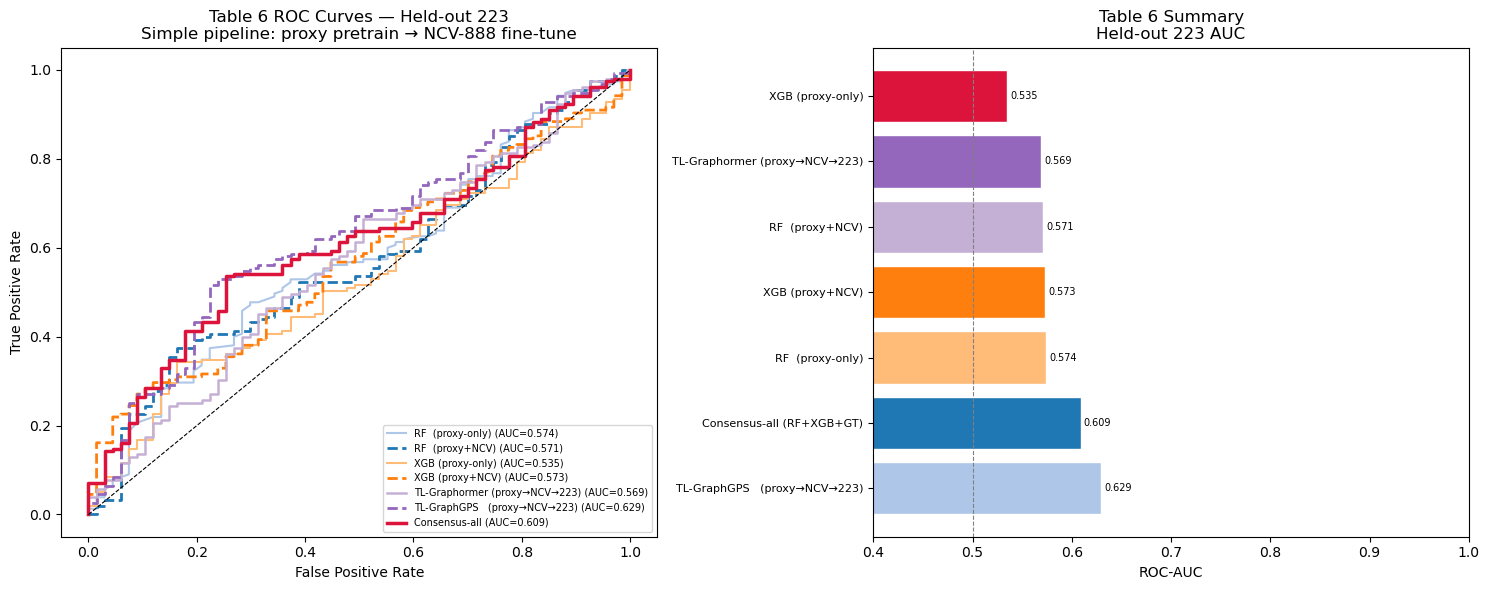

Figure saved → /Users/yaminichitikela/Desktop/qsar casepase/liver/table6_proxy_to_dili_results.png


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ── ROC curves ────────────────────────────────────────────────────────────────
ax = axes[0]
plot_specs = [
    ('RF  (proxy-only)',              p_rf_proxy,  '#aec7e8', '-',   1.5),
    ('RF  (proxy+NCV)',               p_rf_pn,     '#1f77b4', '--',  2.0),
    ('XGB (proxy-only)',              p_xgb_proxy, '#ffbb78', '-',   1.5),
    ('XGB (proxy+NCV)',               p_xgb_pn,    '#ff7f0e', '--',  2.0),
    ('TL-Graphormer (proxy→NCV→223)', p_grph,      '#c5b0d5', '-',   1.8),
    ('TL-GraphGPS   (proxy→NCV→223)', p_gps,       '#9467bd', '--',  2.0),
    ('Consensus-all',                 p_cons_all,  'crimson', '-',   2.5),
]
for name, prob, color, ls, lw in plot_specs:
    fpr, tpr, _ = roc_curve(y_held, prob)
    auc = roc_auc_score(y_held, prob)
    ax.plot(fpr, tpr, color=color, ls=ls, lw=lw,
            label=f'{name} (AUC={auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Table 6 ROC Curves — Held-out 223\n'
             'Simple pipeline: proxy pretrain → NCV-888 fine-tune')
ax.legend(fontsize=7, loc='lower right')

# ── AUC bar chart ─────────────────────────────────────────────────────────────
ax2 = axes[1]
palette = ['#aec7e8', '#1f77b4', '#ffbb78', '#ff7f0e', '#c5b0d5', '#9467bd', 'crimson']
models = df_table6['Model'].tolist()
aucs   = df_table6['ROC-AUC'].tolist()
bars = ax2.barh(range(len(models)), aucs,
                color=palette[:len(models)], edgecolor='white')
ax2.set_yticks(range(len(models)))
ax2.set_yticklabels(models, fontsize=8)
ax2.set_xlabel('ROC-AUC')
ax2.set_title('Table 6 Summary\nHeld-out 223 AUC')
ax2.set_xlim(0.40, 1.0)
ax2.axvline(0.5, color='gray', ls='--', lw=0.8)
for bar, auc in zip(bars, aucs):
    ax2.text(auc + 0.003, bar.get_y() + bar.get_height() / 2,
             f'{auc:.3f}', va='center', fontsize=7)

plt.tight_layout()
out_path = f'{BASE}/liver/table6_proxy_to_dili_results.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved → {out_path}')